In [66]:
import numpy as np
import jax
import jax.numpy as jnp
import pypesto
from pypesto.result import OptimizerResult
import pypesto.profile as profile

import sys
sys.path.insert(0, "../scripts")
import toy_network
import tca_cycle

import pickle
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from jax import config
from matplotlib.lines import Line2D
config.update("jax_enable_x64", True)


import scipy.stats as stats

from cmfa.emu_example import ordered_ilr_func

SEED = 1234
key = jax.random.key(seed=SEED)
key_toy, key = jax.random.split(key)
key_tca, key = jax.random.split(key)

In [67]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [68]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

combined = "#8CAA8D"

In [69]:
# Toy network
simulated_mid_toy = jnp.load(RESULTS_DIR_TOY / "id_simulated_reference.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

with open(RESULTS_DIR_TOY / "estimated_fluxes_sd_reference.pkl", "rb") as f:
    estimated_fluxes_sd_toy = pickle.load(f)

with open(RESULTS_DIR_TOY / "fvalues_reference.pkl", "rb") as f:
    fvals_toy = pickle.load(f)

sim_idx_toy = jax.random.randint(key_toy, 1, 0, 10000).item()

sim_mid_toy = simulated_mid_toy[sim_idx_toy]
sd_trad_toy = np.std(simulated_mid_toy, axis=0)
sd_ilr_toy = np.std(ordered_ilr_func(simulated_mid_toy), axis=0)

flux_est_trad_toy = estimated_fluxes_toy["trad"][sim_idx_toy, [4,5]]
flux_est_ilr_toy = estimated_fluxes_toy["ilr"][sim_idx_toy, [4,5]]

flux_sd_trad_toy = estimated_fluxes_sd_toy["trad"][sim_idx_toy, [4,5]]
flux_sd_ilr_toy = estimated_fluxes_sd_toy["ilr"][sim_idx_toy, [4,5]]

fval_trad_toy = fvals_toy["trad"][sim_idx_toy]
fval_ilr_toy = fvals_toy["ilr"][sim_idx_toy]

In [70]:
# tca cycle
simulated_mid_tca = jnp.load(RESULTS_DIR_TCA / "id_simulated_reference.npy", allow_pickle=True).item()

with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

with open(RESULTS_DIR_TCA / "estimated_fluxes_sd_reference.pkl", "rb") as f:
    estimated_fluxes_sd_tca = pickle.load(f)

with open(RESULTS_DIR_TCA / "fvalues_reference.pkl", "rb") as f:
    fvals_tca = pickle.load(f)

sim_idx_tca = jax.random.randint(key_tca, 1, 0, 10000).item()

sim_mid_tca = jax.tree.map(lambda x: x[sim_idx_tca], simulated_mid_tca)
mid_sd_trad_tca = jax.tree.map(lambda x: np.std(x, axis=0), simulated_mid_tca)
mid_sd_ilr_tca = jax.tree.map(lambda x: np.std(ordered_ilr_func(x), axis=0), simulated_mid_tca)


flux_est_trad_tca = estimated_fluxes_tca["trad"][sim_idx_tca, :]
flux_est_ilr_tca = estimated_fluxes_tca["ilr"][sim_idx_tca, :]

flux_sd_trad_tca = estimated_fluxes_sd_tca["trad"][sim_idx_tca, [0,7,8]]
flux_sd_ilr_tca = estimated_fluxes_sd_tca["ilr"][sim_idx_tca, [0,7,8]]

fval_trad_tca = fvals_tca["trad"][sim_idx_tca]
fval_ilr_tca = fvals_tca["ilr"][sim_idx_tca]

In [71]:
def profile_likelihood_toy(loss_function, sd, observation, opt_flux, opt_fval):
    # 1. Setup Data
    weights = 1/sd

    # 3. Create pyPESTO Objective
    # PyPESTO will call this function as objective(x)
    def my_loss_function(x): 
        return loss_function(x, args=(observation, weights))[0] 

    objective = pypesto.Objective(fun=my_loss_function)

    # 4. Define Problem
    problem = pypesto.Problem(
        objective=objective,
        lb=[-6] * 2, 
        ub=[6] * 2,  
        x_names=['v3', 'v5']
    )

    # 5. Manually inject the Optimistix result into pyPESTO
    result = pypesto.Result(problem=problem)
    opt_result_manual = OptimizerResult(
        x=np.array(np.log(opt_flux)),        # Convert JAX to NumPy
        fval=float(np.array(opt_fval[0])),          # Cast JAX scalar to float
        id="optimistix_bfgs",
    )

    # opt_result_manual = OptimizerResult(
    #     x=flux_est,        # Convert JAX to NumPy
    #     fval=fval_est,          # Cast JAX scalar to float
    #     id="optimistix_bfgs",
    # )
    result.optimize_result.append(opt_result_manual)

    # 6. Profile Likelihood
    # pyPESTO will now use Scipy to "walk" the likelihood surface
    result = profile.parameter_profile(
        problem=problem,
        result=result,
        optimizer=pypesto.optimize.ScipyOptimizer(method="L-BFGS-B"),
    )

    result.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result.profile_result.get_profiler_result(0)["x_path"][0])
    result.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result.profile_result.get_profiler_result(1)["x_path"][1])
    
    return result

def profile_likelihood_tca(loss_function, mid, mid_sd, opt_flux, opt_fval):
    def my_loss_function(x): 
        return loss_function(x, args=(mid, jax.tree.map(lambda s: 1/s, mid_sd)))[0] 

    objective = pypesto.Objective(fun=my_loss_function)

    problem = pypesto.Problem(
        objective=objective,
        lb=[-5] * 3, 
        ub=[5] * 3,  
        x_names=['v8', 'v2', "v9"]
    )

    result = pypesto.Result(problem=problem)
    opt_result_manual = OptimizerResult(
        x=np.log(opt_flux),
        fval=float(np.array(opt_fval)),
        id="optimistix_bfgs",
    )
    result.optimize_result.append(opt_result_manual)

    result = profile.parameter_profile(
        problem=problem,
        result=result,
        optimizer=pypesto.optimize.ScipyOptimizer(),
        filename=None
    )

    result.profile_result.get_profiler_result(0)["x_path"][0] = np.exp(result.profile_result.get_profiler_result(0)["x_path"][0])
    result.profile_result.get_profiler_result(1)["x_path"][1] = np.exp(result.profile_result.get_profiler_result(1)["x_path"][1])
    result.profile_result.get_profiler_result(2)["x_path"][2] = np.exp(result.profile_result.get_profiler_result(2)["x_path"][2])

    return result

def fisher_interval(flux_est, flux_sd):
    mu = np.log(flux_est)
    sigma = flux_sd
    x_start = (mu - 2.4 * sigma)
    x_end = (mu + 2.4 * sigma)
    x_axis = np.linspace(x_start, x_end, 500)
    
    # Calculate Log-Normal PDF
    y_raw = stats.norm.pdf(x_axis, mu, sigma)
    y_scaled = y_raw / np.max(y_raw)

    return np.exp(x_axis), y_scaled


In [55]:
result_trad_toy = profile_likelihood_toy(toy_network.loss_trad, sd_trad_toy, sim_mid_toy, opt_flux=flux_est_trad_toy, opt_fval=fval_trad_toy)
result_ilr_toy = profile_likelihood_toy(toy_network.loss_ilr, sd_ilr_toy, sim_mid_toy, flux_est_ilr_toy, fval_ilr_toy)

100%|██████████| 4/4 [00:09<00:00,  2.48s/it]


In [23]:
result_trad_tca = profile_likelihood_tca(tca_cycle.loss_trad, sim_mid_tca, mid_sd_trad_tca, opt_flux=flux_est_trad_tca, opt_fval=fval_trad_tca)
result_ilr_tca = profile_likelihood_tca(tca_cycle.loss_ilr, sim_mid_tca, mid_sd_ilr_tca, opt_flux=flux_est_ilr_tca, opt_fval=fval_ilr_tca)

100%|██████████| 6/6 [02:37<00:00, 26.23s/it]


In [72]:
est_trad_toy = estimated_fluxes_toy["trad"][:, [4, 5]]
est_ilr_toy = estimated_fluxes_toy["ilr"][:, [4, 5]]

est_trad_tca = estimated_fluxes_tca["trad"]
est_ilr_tca = estimated_fluxes_tca["ilr"]

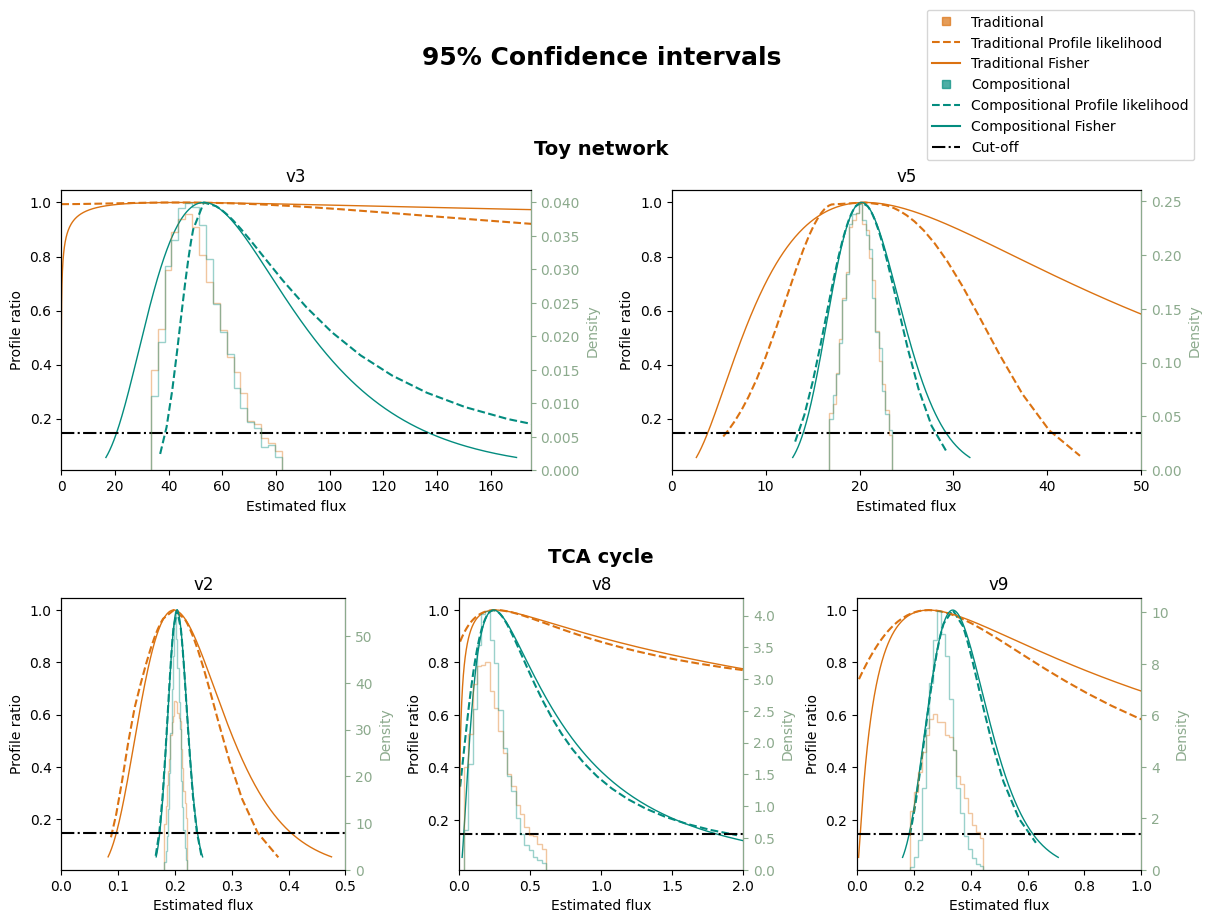

In [75]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
import numpy as np

# Create 1x2 subplots just like your original setup
f = plt.figure(figsize=(12, 8.5)) 

# --- Top Row Setup ---
gs1 = gridspec.GridSpec(1, 2)
gs1.update(left=0.05, right=0.95, top=0.88, bottom=0.55, wspace=0.3) # Adjusted top to fit the title
ax1 = plt.subplot(gs1[0])
ax2 = plt.subplot(gs1[1])

# Add Row Title for Top Row
ax_title1 = f.add_subplot(gs1[:, :], frameon=False)
ax_title1.set_title("Toy network", fontsize=14, fontweight='bold', pad=25)
ax_title1.axis('off') # Hide the axes lines and ticks

# --- Bottom Row Setup ---
gs2 = gridspec.GridSpec(1, 3)
gs2.update(left=0.05, right=0.95, top=0.40, bottom=0.08, hspace=0.05, wspace=0.4) # Adjusted top to fit the title
ax3 = plt.subplot(gs2[0])
ax4 = plt.subplot(gs2[1])
ax5 = plt.subplot(gs2[2])

# Add Row Title for Bottom Row
ax_title2 = f.add_subplot(gs2[:, :], frameon=False)
ax_title2.set_title("TCA cycle", fontsize=14, fontweight='bold', pad=25)
ax_title2.axis('off')

# --- Plotting Loop ---
axes = [ax1, ax2, ax3, ax4, ax5]
tca_flux = ["v8", "v2", "v9"]
tca_idxs = [1,0,2]

for (i, ax) in enumerate(axes):
    if i < 2:
        x_path_trad = result_trad_toy.profile_result.get_profiler_result(i)["x_path"][i]
        ratio_path_trad = result_trad_toy.profile_result.get_profiler_result(i)["ratio_path"]

        x_path_ilr = result_ilr_toy.profile_result.get_profiler_result(i)["x_path"][i]
        ratio_path_ilr = result_ilr_toy.profile_result.get_profiler_result(i)["ratio_path"]
        
        ax.plot(x_path_trad, ratio_path_trad, color=TRAD, linestyle="--", label="Traditional Profile likelihood")
        ax.plot(x_path_ilr, ratio_path_ilr, color=ILR, linestyle="--", label="Compositional Profile likelihood")
        
        x_trad, y_trad = fisher_interval(flux_est_trad_toy[i], flux_sd_trad_toy[i])
        ax.plot(x_trad, y_trad, label='Traditional Fisher information', color=TRAD, lw=1)
        
        x_ilr, y_ilr = fisher_interval(flux_est_ilr_toy[i], flux_sd_ilr_toy[i])
        ax.plot(x_ilr, y_ilr, label='Compositional Fisher information', color=ILR, lw=1)
        
        est_trad_i = est_trad_toy[:, i].flatten()
        est_comp_i = est_ilr_toy[:, i].flatten()
        
        xmin = np.quantile(np.concatenate([est_trad_i, est_comp_i]), 0.025)
        xmax = np.quantile(np.concatenate([est_trad_i, est_comp_i]), 0.975)
        bins = np.linspace(xmin, xmax, 20)
        # 1. Calculate peak-normalization weights for histograms
        counts_trad, _ = np.histogram(est_trad_i, bins=bins)
        counts_ilr, _ = np.histogram(est_comp_i, bins=bins)
        
        weights_trad = np.ones_like(est_trad_i) / np.max(counts_trad)
        weights_ilr = np.ones_like(est_comp_i) / np.max(counts_ilr)

        ax_twin = ax.twinx() 
        h_trad = ax_twin.hist(est_trad_i, bins=bins, histtype='step', color=TRAD, alpha=0.4, density=True, label="Traditional I-MFA")
        h_ilr = ax_twin.hist(est_comp_i, bins=bins, histtype='step', color=ILR, alpha=0.4, density=True, label="Compositional I-MFA")

        ax.axhline(0.1465, color="black", linestyle="-.", label="cut-off")
        ax.set_ylabel("Profile ratio")
        ax_twin.set_ylabel("Density", color=combined)
        ax_twin.spines["right"].set_color(combined)
        ax_twin.tick_params(axis='y', colors=combined)
        
        ax.set(title=f"v{3+2*i}", xlabel="Estimated flux")
    else:
        tca_idx = tca_idxs[i-2]
        
        x_path_trad = result_trad_tca.profile_result.get_profiler_result(tca_idx)["x_path"][tca_idx]
        ratio_path_trad = result_trad_tca.profile_result.get_profiler_result(tca_idx)["ratio_path"]

        x_path_ilr = result_ilr_tca.profile_result.get_profiler_result(tca_idx)["x_path"][tca_idx]
        ratio_path_ilr = result_ilr_tca.profile_result.get_profiler_result(tca_idx)["ratio_path"]
        
        ax.plot(x_path_trad, ratio_path_trad, color=TRAD, linestyle="--", label="Profile Ratio")
        ax.plot(x_path_ilr, ratio_path_ilr, color=ILR, linestyle="--", label="Profile Ratio")
        
        x_trad, y_trad = fisher_interval(flux_est_trad_tca[tca_idx], flux_sd_trad_tca[tca_idx])
        ax.plot(x_trad, y_trad, label='Fisher information', color=TRAD, lw=1)
        
        x_ilr, y_ilr = fisher_interval(flux_est_ilr_tca[tca_idx], flux_sd_ilr_tca[tca_idx])
        ax.plot(x_ilr, y_ilr, label='Fisher information', color=ILR, lw=1)

        est_trad_i = est_trad_tca[:, tca_idx].flatten()
        est_ilr_i = est_ilr_tca[:, tca_idx].flatten()
        
        xmin = np.quantile(np.concatenate([est_trad_i, est_ilr_i]), 0.025)
        xmax = np.quantile(np.concatenate([est_trad_i, est_ilr_i]), 0.975)
        bins = np.linspace(xmin, xmax, 20)
        
        ax_twin = ax.twinx()

        h_trad = ax_twin.hist(est_trad_i, density=True, bins=bins, histtype='step', color=TRAD, alpha=0.4, label="Traditional I-MFA")
        h_ilr = ax_twin.hist(est_ilr_i, density=True, bins=bins, histtype='step', color=ILR, alpha=0.4, label="Compositional I-MFA") 

        ax.set(title=f"{tca_flux[tca_idx]}", xlabel="Estimated flux")
        ax.axhline(0.1465, color="black", linestyle="-.", label="cut-off")
        ax.set_ylabel("Profile ratio")
        ax_twin.set_ylabel("Density", color=combined)
        ax_twin.spines["right"].set_color(combined)
        ax_twin.tick_params(axis='y', colors=combined)

# Set limits for the top row
axes[0].set_xlim(0, 175)
axes[1].set_xlim(0, 50)
axes[2].set_xlim(0,0.5)
axes[3].set_xlim(0,2)
axes[4].set_xlim(0,1)

# --- Legend Setup ---
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="s", linestyle="", markersize=6, alpha=0.7),
    Line2D([0], [0], color=TRAD, linestyle="--", markersize=6, alpha=1),
    Line2D([0], [0], color=TRAD, linestyle="-", markersize=6, alpha=1), 
    Line2D([0], [0], color=ILR, marker="s", linestyle="", markersize=6, alpha=0.7),
    Line2D([0], [0], color=ILR, linestyle="--", markersize=6, alpha=1),
    Line2D([0], [0], color=ILR, linestyle="-", markersize=6, alpha=1),
    Line2D([0], [0], color="black", linestyle="-.", markersize=6, alpha=1),
]

f.legend(custom_marker, 
         ["Traditional","Traditional Profile likelihood", "Traditional Fisher", 
          "Compositional", "Compositional Profile likelihood", "Compositional Fisher", 
          "Cut-off"], 
         fontsize=10, loc="upper right", bbox_to_anchor=(1, 1.1))

plt.savefig(PLOT_DIR / 'CI.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
f.suptitle("95% Confidence intervals", fontsize=18, fontweight='bold', y=1.05)
plt.show()